In [1]:
from pathlib import Path

import pandas as pd


# Precision/Recall/F1

Replicate test2's evaluation for the curated DGIdb Qwen3 14B run using the same 100-interaction truth set. Run this notebook from its own directory.

The main precision/recall/F1 scores evaluate generated PMID–drug–gene candidates, matching test2. Truth interactions with no generated prediction are counted separately in the recovery analysis and the outer-joined review workbook. Matching uses uppercase, stripped names without synonym resolution; DGIdb-unmatched positive predictions are labeled FP for review.


### Load Data


Load the Qwen3 14B classifications and the same curated truth/context workbook used by test2.


In [2]:
results_df = pd.read_csv('interaction_classifications-rohit-qwen3-14b.csv',sep=',')
context_df = pd.read_excel('../../../data/2026-06-29-test2-RohitList-wText.xlsx')

truth_df = context_df.copy()
pred_df = results_df.copy()

In [3]:
pred_df.head()

,model_id,max_tokens,enable_thinking,backend,device,quantization_bits,run_idx,prompt_version,temperature,used_raw_drug_candidates,...,raw_gene_count,result_error_message,drug,gene,interaction,interaction_type,directionality,evidence,classification_error_message,error_message
0,mlx-community/Qwen3-14B-4bit,1000,False,mlx,metal,4,0,v2,0,False,...,3,NaN,dabrafenib,BRAF,True,inhibition,inhibiting,Dabrafenib is an inhibitor of BRAF kinase that...,NaN,NaN
1,mlx-community/Qwen3-14B-4bit,1000,False,mlx,metal,4,0,v2,0,False,...,3,NaN,dabrafenib,BRAF,True,inhibition,inhibiting,"Dabrafenib, an inhibitor of mutated BRAF, has ...",NaN,NaN
2,mlx-community/Qwen3-14B-4bit,1000,False,mlx,metal,4,0,v2,0,False,...,3,NaN,dacarbazine,BRAF,False,NaN,NaN,NaN,No direct evidence of interaction between daca...,No direct evidence of interaction between daca...
3,mlx-community/Qwen3-14B-4bit,1000,False,mlx,metal,4,0,v2,0,False,...,8,NaN,avapritinib,BRAF,False,NaN,NaN,NaN,No direct evidence of interaction between avap...,No direct evidence of interaction between avap...
4,mlx-community/Qwen3-14B-4bit,1000,False,mlx,metal,4,0,v2,0,False,...,8,NaN,dabrafenib,BRAF,True,inhibiting,drug inhibits gene product,This therapy led to a partial response.,NaN,NaN


In [4]:
truth_df.head()

,Unnamed: 0,pmid,drug_name,gene_name,context
0,0,22608338,DABRAFENIB,BRAF,BACKGROUND: Dabrafenib is an inhibitor of BRAF...
1,1,22735384,DABRAFENIB,BRAF,"BACKGROUND: Dabrafenib, an inhibitor of mutate..."
2,2,38756640,DABRAFENIB,BRAF,BACKGROUND: Gastrointestinal stromal tumor (GI...
3,3,24508103,VEMURAFENIB,BRAF,"BACKGROUND: In the BRIM-3 trial, vemurafenib w..."
4,4,27460442,VEMURAFENIB,BRAF,BACKGROUND: About half of patients with papill...


In [5]:
pred_df['gene'].value_counts(dropna=False)

gene
EGFR      16
ACE       13
ROS1      13
FLT3      13
BRAF      12
KRAS      11
ALK       11
RET       10
KIT        9
IDH2       7
TOP1       7
FGFR2      7
FGFR3      6
NaN        6
JAK2       5
HMGCR      5
NRAS       5
PDGFRA     5
CDKN2A     5
ATM        4
GNA11      4
IDH1       4
VDR        4
ERBB2      4
JAK3       3
CSF3R      3
MAP2K1     3
PIK3CA     3
KDR        3
SMO        2
TSC1       1
FGFR1      1
TSC2       1
Name: count, dtype: int64

In [6]:
print(f"Total drug candidates found: {pred_df['gene'].notnull().sum()}")

Total drug candidates found: 200


In [7]:
print(f"Number of PMIDs present in the curated DGIdb truth set: {truth_df['pmid'].nunique()}")
print(f"Number of genes in the truth set: {truth_df['gene_name'].nunique()}")
print(f"Skipped prediction rows: {pred_df['skipped'].sum()}")


Number of PMIDs present in the curated DGIdb truth set: 100
Number of genes in the truth set: 32
Skipped prediction rows: 6


Analysis

In [8]:
truth = truth_df.copy()
pred = pred_df.copy()

truth["drug"] = truth["drug_name"].str.upper().str.strip()
truth["gene"] = truth["gene_name"].str.upper().str.strip()

pred["drug"] = pred["drug"].str.upper().str.strip()
pred["gene"] = pred["gene"].str.upper().str.strip()

In [9]:
truth_pairs = (
    truth[
        ["pmid", "drug", "gene"]
    ]
    .drop_duplicates()
)

truth_pairs["truth"] = True

In [10]:
pred_pairs = (
    pred[
        ["pmid", "drug", "gene", "interaction"]
    ]
    .drop_duplicates()
)

pred_pairs = pred_pairs.rename(
    columns={"interaction": "predicted"}
)

In [11]:
pred_pairs = pred_pairs.dropna(subset=["pmid", "drug", "gene"])
truth_pairs = truth_pairs.dropna(subset=["pmid", "drug", "gene"])

In [12]:
eval_df = pred_pairs.merge(
    truth_pairs,
    on=["pmid", "drug", "gene"],
    how="left"
)

eval_df["truth"] = eval_df["truth"].eq(True)

In [13]:
pred_df

,model_id,max_tokens,enable_thinking,backend,device,quantization_bits,run_idx,prompt_version,temperature,used_raw_drug_candidates,...,raw_gene_count,result_error_message,drug,gene,interaction,interaction_type,directionality,evidence,classification_error_message,error_message
0,mlx-community/Qwen3-14B-4bit,1000,False,mlx,metal,4,0,v2,0,False,...,3,NaN,dabrafenib,BRAF,True,inhibition,inhibiting,Dabrafenib is an inhibitor of BRAF kinase that...,NaN,NaN
1,mlx-community/Qwen3-14B-4bit,1000,False,mlx,metal,4,0,v2,0,False,...,3,NaN,dabrafenib,BRAF,True,inhibition,inhibiting,"Dabrafenib, an inhibitor of mutated BRAF, has ...",NaN,NaN
2,mlx-community/Qwen3-14B-4bit,1000,False,mlx,metal,4,0,v2,0,False,...,3,NaN,dacarbazine,BRAF,False,NaN,NaN,NaN,No direct evidence of interaction between daca...,No direct evidence of interaction between daca...
3,mlx-community/Qwen3-14B-4bit,1000,False,mlx,metal,4,0,v2,0,False,...,8,NaN,avapritinib,BRAF,False,NaN,NaN,NaN,No direct evidence of interaction between avap...,No direct evidence of interaction between avap...
4,mlx-community/Qwen3-14B-4bit,1000,False,mlx,metal,4,0,v2,0,False,...,8,NaN,dabrafenib,BRAF,True,inhibiting,drug inhibits gene product,This therapy led to a partial response.,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
201,mlx-community/Qwen3-14B-4bit,1000,False,mlx,metal,4,0,v2,0,False,...,8,NaN,cabozantinib s-malate,ROS1,True,sensitivity,inhibiting,"In Ba/F3 models, ROS1L2086F, ROS1G2032R/L2086F...",NaN,NaN
202,mlx-community/Qwen3-14B-4bit,1000,False,mlx,metal,4,0,v2,0,False,...,8,NaN,crizotinib,ROS1,True,drug resistance,inhibiting,ROS1 mutations were identified in 38% of post-...,NaN,NaN
203,mlx-community/Qwen3-14B-4bit,1000,False,mlx,metal,4,0,v2,0,False,...,8,NaN,entrectinib,ROS1,True,inhibitory,inhibits,Structural modeling predicted ROS1L2086F cause...,NaN,NaN
204,mlx-community/Qwen3-14B-4bit,1000,False,mlx,metal,4,0,v2,0,False,...,8,NaN,lorlatinib,ROS1,True,drug resistance,inhibiting,"ROS1L2086F, ROS1G2032R/L2086F, and ROS1S1986F/...",NaN,NaN


In [14]:
eval_df

,pmid,drug,gene,predicted,truth
0,22608338,DABRAFENIB,BRAF,True,True
1,22735384,DABRAFENIB,BRAF,True,True
2,22735384,DACARBAZINE,BRAF,False,False
3,38756640,AVAPRITINIB,BRAF,False,False
4,38756640,DABRAFENIB,BRAF,True,True
...,...,...,...,...,...
195,33685866,CABOZANTINIB S-MALATE,ROS1,True,False
196,33685866,CRIZOTINIB,ROS1,True,False
197,33685866,ENTRECTINIB,ROS1,True,False
198,33685866,LORLATINIB,ROS1,True,True


In [15]:
eval_df["predicted"].value_counts(dropna=False)

predicted
True     131
False     69
Name: count, dtype: int64

In [16]:
tp = ((eval_df["truth"] == True) & (eval_df["predicted"] == True)).sum()
fp = ((eval_df["truth"] == False) & (eval_df["predicted"] == True)).sum()
tn = ((eval_df["truth"] == False) & (eval_df["predicted"] == False)).sum()
fn = ((eval_df["truth"] == True) & (eval_df["predicted"] == False)).sum()

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
accuracy = (tp + tn) / (tp + fp + tn + fn) if tp + fp + tn + fn else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

pd.Series({
    "tp": tp,
    "fp": fp,
    "tn": tn,
    "fn": fn,
    "precision": precision,
    "recall": recall,
    "accuracy": accuracy,
    "f1": f1,
})

tp           84.000000
fp           47.000000
tn           69.000000
fn            0.000000
precision     0.641221
recall        1.000000
accuracy      0.765000
f1            0.781395
dtype: float64

Matplotlib is building the font cache; this may take a moment.


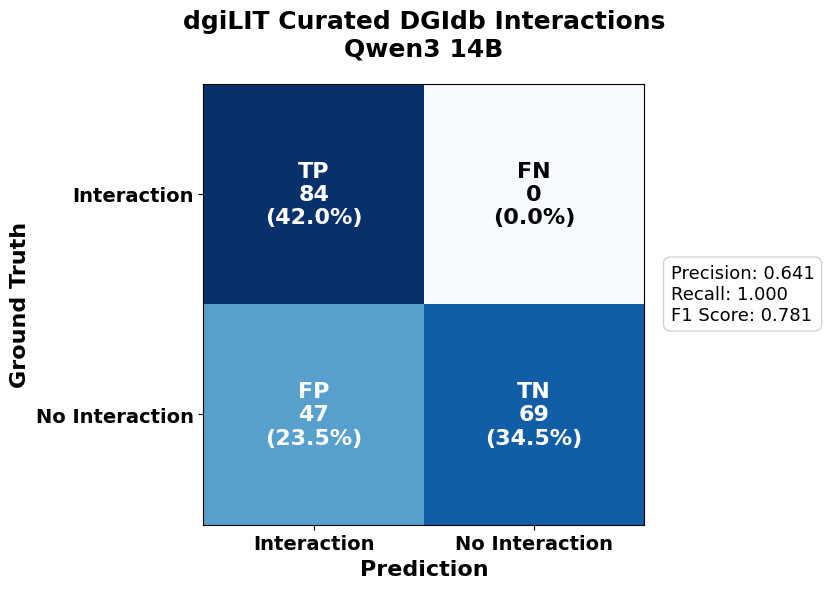

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------
# Confusion matrix values
# ------------------------------------------------------------------

tp = ((eval_df["truth"] == True) & (eval_df["predicted"] == True)).sum()
fp = ((eval_df["truth"] == False) & (eval_df["predicted"] == True)).sum()
tn = ((eval_df["truth"] == False) & (eval_df["predicted"] == False)).sum()
fn = ((eval_df["truth"] == True) & (eval_df["predicted"] == False)).sum()

cm = np.array([
    [tp, fn],
    [fp, tn]
])

total = cm.sum()

# ------------------------------------------------------------------
# Metrics
# ------------------------------------------------------------------

precision = tp / (tp + fp) if (tp + fp) else 0
recall = tp / (tp + fn) if (tp + fn) else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall)
    else 0
)

# ------------------------------------------------------------------
# Plot
# ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(cm, cmap="Blues")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(
    ["Interaction", "No Interaction"],
    fontsize=14,
    fontweight="bold"
)

ax.set_yticklabels(
    ["Interaction", "No Interaction"],
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Prediction",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel(
    "Ground Truth",
    fontsize=16,
    fontweight="bold"
)

ax.set_title(
    "dgiLIT Curated DGIdb Interactions\nQwen3 14B",
    fontsize=18,
    fontweight="bold",
    pad=20,
)

# ------------------------------------------------------------------
# Cell annotations
# ------------------------------------------------------------------

for i in range(2):
    for j in range(2):

        count = cm[i, j]
        pct = (count / total) * 100 if total else 0

        label = (
            "TP" if (i == 0 and j == 0)
            else "FN" if (i == 0 and j == 1)
            else "FP" if (i == 1 and j == 0)
            else "TN"
        )

        ax.text(
            j,
            i,
            f"{label}\n{count}\n({pct:.1f}%)",
            ha="center",
            va="center",
            fontsize=16,
            fontweight="bold",
            color="white" if count > cm.max() * 0.55 else "black",
        )

# ------------------------------------------------------------------
# Metrics box
# ------------------------------------------------------------------

metrics_text = (
    f"Precision: {precision:.3f}\n"
    f"Recall: {recall:.3f}\n"
    f"F1 Score: {f1:.3f}"
)

plt.figtext(
    0.88,
    0.50,
    metrics_text,
    fontsize=13,
    va="center",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="lightgray"
    ),
)

# Clean up appearance
ax.set_aspect("equal")

plt.tight_layout()

# Uncomment for manuscript-quality export
# plt.savefig(
#     "qwen3_14b_confusion_matrix.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

In [18]:
# End-to-end recovery includes truth pairs with no generated candidate.
truth_set = set(truth_pairs[["pmid", "drug", "gene"]].itertuples(index=False, name=None))
predicted_set = set(
    pred_pairs.loc[pred_pairs["predicted"] == True, ["pmid", "drug", "gene"]]
    .itertuples(index=False, name=None)
)
recovered = truth_set & predicted_set
recovery_rate = len(recovered) / len(truth_set) if truth_set else 0
print(f"Recovered {len(recovered)} of {len(truth_set)} interactions ({recovery_rate:.1%})")


Recovered 84 of 100 interactions (84.0%)


### Review and recovery workbooks

Evaluate all curated genes. Missing truth predictions count as false negatives in these workbooks. Candidate presence follows test2's semicolon-separated drug lists per PMID.


In [19]:
import pandas as pd
import numpy as np

# ------------------------------------------------------------------
# Helpers
# ------------------------------------------------------------------

def norm_text(x):
    if pd.isna(x):
        return np.nan
    return str(x).upper().strip()

def candidate_contains_drug(candidate_string, drug):
    if pd.isna(candidate_string) or pd.isna(drug):
        return False

    candidates = {
        norm_text(x)
        for x in str(candidate_string).split(";")
        if str(x).strip()
    }

    return norm_text(drug) in candidates


# ------------------------------------------------------------------
# Normalize truth and prediction data
# ------------------------------------------------------------------

truth_norm = truth_df.copy()
truth_norm["drug"] = truth_norm["drug_name"].map(norm_text)
truth_norm["gene"] = truth_norm["gene_name"].map(norm_text)
truth_norm = truth_norm.dropna(subset=["pmid", "drug", "gene"])

pred_norm = pred_df.copy()
pred_norm["drug"] = pred_norm["drug"].map(norm_text)
pred_norm["gene"] = pred_norm["gene"].map(norm_text)

# Drop skipped / empty prediction rows
pred_norm = pred_norm.dropna(subset=["pmid", "drug", "gene"])

truth_pairs = (
    truth_norm[["pmid", "drug", "gene"]]
    .drop_duplicates()
    .assign(truth=True)
)

pred_pairs = (
    pred_norm[["pmid", "drug", "gene", "interaction"]]
    .drop_duplicates()
    .rename(columns={"interaction": "predicted"})
)

# ------------------------------------------------------------------
# Build evaluation table
# ------------------------------------------------------------------

eval_full = truth_pairs.merge(
    pred_pairs,
    on=["pmid", "drug", "gene"],
    how="outer"
)

eval_full["truth"] = eval_full["truth"].eq(True)
eval_full["predicted"] = eval_full["predicted"].eq(True)

eval_full["classification"] = np.select(
    [
        (eval_full["truth"] == True) & (eval_full["predicted"] == True),
        (eval_full["truth"] == False) & (eval_full["predicted"] == True),
        (eval_full["truth"] == False) & (eval_full["predicted"] == False),
        (eval_full["truth"] == True) & (eval_full["predicted"] == False),
    ],
    ["TP", "FP", "TN", "FN"],
    default="UNKNOWN"
)

# ------------------------------------------------------------------
# Add prediction details
# ------------------------------------------------------------------

pred_details = pred_norm[
    [
        "pmid",
        "block_id",
        "drug",
        "gene",
        "candidate_drugs",
        "candidate_genes",
        "interaction",
        "interaction_type",
        "directionality",
        "evidence",
        "error_message",
    ]
].drop_duplicates(subset=["pmid", "drug", "gene"])

review_df = eval_full.merge(
    pred_details,
    on=["pmid", "drug", "gene"],
    how="left"
)

# Add truth context / metadata
truth_detail_cols = [
    "pmid",
    "drug",
    "gene",
    "drug_name",
    "gene_name",
            "context",
]

truth_detail_cols = [
    col for col in truth_detail_cols
    if col in truth_norm.columns
]

truth_details = (
    truth_norm[truth_detail_cols]
    .drop_duplicates(subset=["pmid", "drug", "gene"])
)

review_df = review_df.merge(
    truth_details,
    on=["pmid", "drug", "gene"],
    how="left"
)

# If context is missing for FP rows, try to recover PMID-level context from truth_df
pmid_context = (
    truth_norm[["pmid", "context"]]
    .drop_duplicates(subset=["pmid"])
    .rename(columns={"context": "pmid_context"})
)

review_df = review_df.merge(
    pmid_context,
    on="pmid",
    how="left"
)

review_df["review_context"] = review_df["context"].fillna(review_df["pmid_context"])

# Manual review fields
review_df["manual_review"] = ""
review_df["manual_notes"] = ""

# ------------------------------------------------------------------
# FP / FN workbook
# ------------------------------------------------------------------

fp_df = review_df[review_df["classification"] == "FP"].copy()
fn_df = review_df[review_df["classification"] == "FN"].copy()

fp_columns = [
    "classification",
    "pmid",
    "drug",
    "gene",
    "predicted",
    "truth",
    "interaction_type",
    "directionality",
    "evidence",
    "candidate_drugs",
    "candidate_genes",
    "review_context",
    "manual_review",
    "manual_notes",
]

fn_columns = [
    "classification",
    "pmid",
    "drug",
    "gene",
    "predicted",
    "truth",
    "candidate_drugs",
    "candidate_genes",
    "drug_name",
            "review_context",
    "manual_review",
    "manual_notes",
]

with pd.ExcelWriter("qwen3_14b_fp_fn_manual_review.xlsx", engine="xlsxwriter") as writer:
    fp_df[fp_columns].to_excel(writer, sheet_name="False Positives", index=False)
    fn_df[fn_columns].to_excel(writer, sheet_name="False Negatives", index=False)
    review_df.to_excel(writer, sheet_name="All Evaluated Pairs", index=False)

    workbook = writer.book

    for sheet_name in writer.sheets:
        worksheet = writer.sheets[sheet_name]
        worksheet.freeze_panes(1, 0)
        worksheet.autofilter(0, 0, worksheet.dim_rowmax, worksheet.dim_colmax)
        worksheet.set_column(0, 5, 14)
        worksheet.set_column(6, 10, 24)
        worksheet.set_column(11, 11, 80)
        worksheet.set_column(12, 13, 24)


# ------------------------------------------------------------------
# Interaction recovery workbook
# ------------------------------------------------------------------

# One row per original truth interaction
recovery_df = truth_norm[
    [
        "pmid",
        "drug",
        "gene",
        "drug_name",
        "gene_name",
                        "context",
    ]
].drop_duplicates(subset=["pmid", "drug", "gene"]).copy()

# Add candidate drug list per PMID
candidate_by_pmid = (
    pred_norm[["pmid", "candidate_drugs"]]
    .dropna()
    .drop_duplicates(subset=["pmid"])
)

recovery_df = recovery_df.merge(
    candidate_by_pmid,
    on="pmid",
    how="left"
)

recovery_df["candidate_present"] = recovery_df.apply(
    lambda row: candidate_contains_drug(row["candidate_drugs"], row["drug"]),
    axis=1
)

# Add predicted status for exact PMID-drug-gene pair
recovery_df = recovery_df.merge(
    pred_pairs,
    on=["pmid", "drug", "gene"],
    how="left"
)

recovery_df["predicted"] = recovery_df["predicted"].eq(True)

recovery_df["recovered"] = (
    (recovery_df["candidate_present"] == True)
    & (recovery_df["predicted"] == True)
)

recovery_df["failure_mode"] = np.select(
    [
        recovery_df["recovered"] == True,
        recovery_df["candidate_present"] == False,
        (recovery_df["candidate_present"] == True) & (recovery_df["predicted"] == False),
    ],
    [
        "Recovered",
        "Candidate drug not generated",
        "Candidate generated but classifier returned false",
    ],
    default="Unclear"
)

recovery_df["manual_review"] = ""
recovery_df["manual_notes"] = ""

missed_recovery_df = recovery_df[recovery_df["recovered"] == False].copy()

summary_df = pd.DataFrame(
    {
        "metric": [
            "Total truth interactions",
            "Candidate present",
            "Recovered",
            "Missed",
            "Candidate recall",
            "Interaction recovery rate",
            "Classifier recall given candidate present",
        ],
        "value": [
            len(recovery_df),
            int(recovery_df["candidate_present"].sum()),
            int(recovery_df["recovered"].sum()),
            int((~recovery_df["recovered"]).sum()),
            recovery_df["candidate_present"].mean(),
            recovery_df["recovered"].mean(),
            (
                recovery_df["recovered"].sum()
                / recovery_df["candidate_present"].sum()
                if recovery_df["candidate_present"].sum() > 0
                else np.nan
            ),
        ],
    }
)

with pd.ExcelWriter("qwen3_14b_interaction_recovery_review.xlsx", engine="xlsxwriter") as writer:
    summary_df.to_excel(writer, sheet_name="Summary", index=False)
    recovery_df.to_excel(writer, sheet_name="All Truth Interactions", index=False)
    missed_recovery_df.to_excel(writer, sheet_name="Missed Interactions", index=False)

    workbook = writer.book

    for sheet_name in writer.sheets:
        worksheet = writer.sheets[sheet_name]
        worksheet.freeze_panes(1, 0)
        worksheet.autofilter(0, 0, worksheet.dim_rowmax, worksheet.dim_colmax)
        worksheet.set_column(0, 8, 18)
        worksheet.set_column(9, 9, 50)
        worksheet.set_column(10, 10, 80)
        worksheet.set_column(11, 15, 24)


print("Saved:")
print("qwen3_14b_fp_fn_manual_review.xlsx")
print("qwen3_14b_interaction_recovery_review.xlsx")
print()
print(summary_df)

Saved:
qwen3_14b_fp_fn_manual_review.xlsx
qwen3_14b_interaction_recovery_review.xlsx

                                      metric   value
0                   Total truth interactions  100.00
1                          Candidate present   84.00
2                                  Recovered   84.00
3                                     Missed   16.00
4                           Candidate recall    0.84
5                  Interaction recovery rate    0.84
6  Classifier recall given candidate present    1.00


### Optional human review scores

To enable human-corrected scoring, save a reviewed copy as `qwen3_14b_fp_fn_manual_review-human.xlsx` beside this notebook. Its `False Positives` sheet must contain `pmid`, `drug`, `gene`, and a Boolean `human_truth` column. Until then, these cells skip scoring. Human corrections apply to the same generated-candidate evaluation as the primary metrics.


In [20]:
human_review_path = Path("qwen3_14b_fp_fn_manual_review-human.xlsx")
if human_review_path.exists():
    human_review_df = pd.read_excel(human_review_path, sheet_name="False Positives")
    human_review_df["drug"] = human_review_df["drug"].str.upper().str.strip()
    human_review_df["gene"] = human_review_df["gene"].str.upper().str.strip()

    human_lookup = human_review_df[
        ["pmid", "drug", "gene", "human_truth"]
    ].copy()

    eval_human = eval_df.merge(
        human_lookup,
        on=["pmid", "drug", "gene"],
        how="left"
    )

    eval_human["truth_star"] = eval_human["truth"]

    mask = (
        (eval_human["truth"] == False)
        & (eval_human["human_truth"].notna())
    )

    eval_human.loc[mask, "truth_star"] = (
        eval_human.loc[mask, "human_truth"]
    )

    tp_star = (
        (eval_human["truth_star"] == True)
        & (eval_human["predicted"] == True)
    ).sum()

    fp_star = (
        (eval_human["truth_star"] == False)
        & (eval_human["predicted"] == True)
    ).sum()

    tn_star = (
        (eval_human["truth_star"] == False)
        & (eval_human["predicted"] == False)
    ).sum()

    fn_star = (
        (eval_human["truth_star"] == True)
        & (eval_human["predicted"] == False)
    ).sum()

else:
    print(f"Human-corrected scoring skipped: {human_review_path.name} is not present.")


Human-corrected scoring skipped: qwen3_14b_fp_fn_manual_review-human.xlsx is not present.


In [21]:
if human_review_path.exists():
    import numpy as np
    import matplotlib.pyplot as plt

    # ------------------------------------------------------------------
    # Human-corrected confusion matrix values
    # ------------------------------------------------------------------

    tp_star = (
        (eval_human["truth_star"] == True)
        & (eval_human["predicted"] == True)
    ).sum()

    fp_star = (
        (eval_human["truth_star"] == False)
        & (eval_human["predicted"] == True)
    ).sum()

    tn_star = (
        (eval_human["truth_star"] == False)
        & (eval_human["predicted"] == False)
    ).sum()

    fn_star = (
        (eval_human["truth_star"] == True)
        & (eval_human["predicted"] == False)
    ).sum()

    print(
        f"TP*: {tp_star}\n"
        f"FP*: {fp_star}\n"
        f"TN*: {tn_star}\n"
        f"FN*: {fn_star}"
    )

    cm = np.array([
        [tp_star, fn_star],
        [fp_star, tn_star]
    ])

    total = cm.sum()

    # ------------------------------------------------------------------
    # Metrics
    # ------------------------------------------------------------------

    precision_star = (
        tp_star / (tp_star + fp_star)
        if (tp_star + fp_star)
        else 0
    )

    recall_star = (
        tp_star / (tp_star + fn_star)
        if (tp_star + fn_star)
        else 0
    )

    f1_star = (
        2 * precision_star * recall_star
        / (precision_star + recall_star)
        if (precision_star + recall_star)
        else 0
    )

    # ------------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------------

    fig, ax = plt.subplots(figsize=(8, 6))

    im = ax.imshow(cm, cmap="Blues")

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(
        ["Interaction", "No Interaction"],
        fontsize=14,
        fontweight="bold"
    )

    ax.set_yticklabels(
        ["Interaction", "No Interaction"],
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Prediction",
        fontsize=16,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Human-Corrected Ground Truth",
        fontsize=16,
        fontweight="bold"
    )

    ax.set_title(
        "dgiLIT Pairwise Classification of Curated DGIdb Interactions (Qwen3 14B)\n(Human-Corrected Evaluation)",
        fontsize=18,
        fontweight="bold",
        pad=20,
    )

    # ------------------------------------------------------------------
    # Cell annotations
    # ------------------------------------------------------------------

    for i in range(2):
        for j in range(2):

            count = cm[i, j]
            pct = (count / total) * 100 if total else 0

            label = (
                "TP*" if (i == 0 and j == 0)
                else "FN*" if (i == 0 and j == 1)
                else "FP*" if (i == 1 and j == 0)
                else "TN*"
            )

            ax.text(
                j,
                i,
                f"{label}\n{count}\n({pct:.1f}%)",
                ha="center",
                va="center",
                fontsize=16,
                fontweight="bold",
                color="white" if count > cm.max() * 0.55 else "black",
            )

    # ------------------------------------------------------------------
    # Metrics box
    # ------------------------------------------------------------------

    metrics_text = (
        f"Precision*: {precision_star:.3f}\n"
        f"Recall*: {recall_star:.3f}\n"
        f"F1 Score*: {f1_star:.3f}"
    )

    plt.figtext(
        0.88,
        0.50,
        metrics_text,
        fontsize=13,
        va="center",
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            edgecolor="lightgray"
        ),
    )

    ax.set_aspect("equal")

    plt.tight_layout()

    # Uncomment to save
    # plt.savefig(
    #     "qwen3_14b_confusion_matrix_human_corrected.png",
    #     dpi=300,
    #     bbox_inches="tight"
    # )

    plt.show()